# Notebook 10 — Pares de entrenamiento para el cWGAN-GP de super-resolución (Paper 2)

Genera los pares (muograma de **corta exposición**, muograma de **larga exposición**)
que alimentarán al cWGAN-GP de super-resolución (núcleo del Paper 2, siguiendo a
O'Donnell et al. 2025, arXiv:2502.02624). Antes de generar los pares, valida que
adelgazar (binomial thinning) el pool de muones de una corrida se comporta
estadísticamente como una corrida CORSIKA real e independiente más corta — si no
fuera así, todo el esquema de pares estaría construido sobre una suposición falsa.

**Por qué "fracción de estadística MC" y no "días de exposición":** no tenemos
definido el tipo de detector (área efectiva, aceptancia angular) para este proyecto,
así que todavía no hay una traducción real a tiempo de exposición. En vez de asumir
un valor de detector, la exposición corta se define como fracción de la estadística
MC ya simulada (mismo patrón que la Sección 6b de NB09 y el sweep de NSHOW de NB02).

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Transformer
from scipy import stats

from analysis.muograma import DEMTerrain, rock_opacity_grid, mc_transmission_map

RNG = np.random.default_rng(20260715)

## 1. Tabla de muones pool-eada por volcán

Reutiliza el mismo pool de las 16 corridas de producción que NB09 (`sim/runs.csv` en
alcyon). Como los DAT crudos (~3 GB) viven solo en alcyon, se extrajo de ahí una tabla
liviana (θ, p, corrida, volcán) — ver `sim/output/muon_table_lightweight.parquet`
(gitignored; regenerar con el bloque de extracción documentado en la celda de abajo
si no existe).

In [2]:
MUON_TABLE_PATH = REPO_ROOT / "sim/output/muon_table_lightweight.parquet"
if not MUON_TABLE_PATH.exists():
    raise FileNotFoundError(
        f"Falta {MUON_TABLE_PATH}. Extraer en alcyon (dentro del contenedor thesis-ml):\n"
        "  import pandas as pd, numpy as np\n"
        "  from analysis.corsika import CorsikaRun\n"
        "  runs = pd.read_csv('/work/sim/runs.csv')\n"
        "  frames = []\n"
        "  for _, r in runs.iterrows():\n"
        "      run = CorsikaRun('/work/sim/output', run_number=int(r.runnr))\n"
        "      mu = run.particles.muons()\n"
        "      p = np.sqrt(mu['px']**2 + mu['py']**2 + mu['pz']**2)\n"
        "      theta = np.degrees(np.arccos(np.clip(np.abs(mu['pz']) / p, -1, 1)))\n"
        "      frames.append(pd.DataFrame({'runnr': int(r.runnr), 'volcan': r.volcan,\n"
        "                                   'nshow': int(r.nshow), 'theta_deg': theta, 'p_gevc': p}))\n"
        "  pd.concat(frames, ignore_index=True).to_parquet('/work/sim/output/muon_table_lightweight.parquet')\n"
        "y copiar el .parquet a esta ruta (scp / rsync)."
    )

muons = pd.read_parquet(MUON_TABLE_PATH)
print(f"Pool total: {len(muons):,} muones")
print(muons.groupby("volcan").size().rename("n_muones"))

Pool total: 333,979 muones
volcan
acatenango     79587
agua           76275
fuego         106281
pacaya         71836
Name: n_muones, dtype: int64


## 2. Geometría DEM por volcán (grid angular + opacidad)

Mismo setup que NB05/NB07: DEM de Copernicus, posición del detector desde la estación
INSIVUMEH-RSN por defecto de cada volcán (`data/volcanoes.yaml` /
`data/detector_sites.csv`), grid angular θ∈[40°,85°] × φ (ventana de 120° centrada en
la cima), paso 0.5° (grid 91×241, igual que Paper 1).

In [3]:
with open(REPO_ROOT / "data/volcanoes.yaml") as f:
    VOLCANOES = yaml.safe_load(f)
sites = pd.read_csv(REPO_ROOT / "data/detector_sites.csv")
DEM_FILE = REPO_ROOT / "data/dem/Copernicus_DSM_COG_10_N14_00_W091_00_DEM.tif"


def build_geometry(target_volcan):
    cfg = VOLCANOES[target_volcan]
    station = cfg["default_station"]
    terrain = DEMTerrain(DEM_FILE, origin_lonlat=(cfg["lon"], cfg["lat"]),
                         density_gcc=cfg["cone"]["density_gcc"])
    site = sites[(sites["name"] == station) & (sites["target_volcan"] == target_volcan)].iloc[0]

    tx = Transformer.from_crs("EPSG:4326", f"EPSG:{terrain.utm_epsg}", always_xy=True)
    e_utm, n_utm = tx.transform(site["lon"], site["lat"])
    det_x, det_y = float(e_utm - terrain.origin_utm[0]), float(n_utm - terrain.origin_utm[1])
    det_z = float(terrain.elevation_at(np.array(det_x), np.array(det_y))) + 2.0
    detector_xyz = (det_x, det_y, det_z)

    dx, dy = -det_x, -det_y
    phi_summit_deg = np.degrees(np.arctan2(dy, dx)) % 360.0

    theta_deg = np.arange(40.0, 85.5, 0.5)
    phi_deg = np.arange(phi_summit_deg - 60.0, phi_summit_deg + 60.5, 0.5)
    theta_rad, phi_rad = np.radians(theta_deg), np.radians(phi_deg)

    L_dem = rock_opacity_grid(terrain, detector_xyz, theta_rad, phi_rad,
                              max_length_m=8_000.0, n_steps=400)
    return theta_rad, phi_rad, L_dem, station


geoms = {}
for volcan in ["fuego", "acatenango", "pacaya", "agua"]:
    geoms[volcan] = build_geometry(volcan)
    theta_rad, phi_rad, L_dem, station = geoms[volcan]
    print(f"{volcan:11s} grid {L_dem.shape}  estación {station}  roca en {(L_dem > 0).mean():.1%} de los píxeles")

fuego       grid (91, 241)  estación FG16  roca en 33.5% de los píxeles


acatenango  grid (91, 241)  estación FG16  roca en 34.0% de los píxeles


pacaya      grid (91, 241)  estación PCG  roca en 44.9% de los píxeles


agua        grid (91, 241)  estación SAOB  roca en 13.4% de los píxeles


## 3. Validación: ¿el thinning binomial se comporta como una corrida real más corta?

Fuego es el único volcán con un sweep real de NSHOW independiente (runs 1-6: 5k a
100k, más la producción a 150k) — eso permite una comparación honesta: adelgazar el
pool completo de Fuego (excluyendo la corrida real que se usa de referencia, para no
hacer trampa) hasta el mismo tamaño que la corrida real de 50k (RUNNR 5, 14,760
muones) y comparar ambas con un test de Kolmogorov-Smirnov y con el propio `T_mc`
— el observable físico que realmente importa, no solo la distribución (θ,p) cruda.

In [4]:
fuego_pool = muons[muons["volcan"] == "fuego"]
real_run5 = fuego_pool[fuego_pool["runnr"] == 5]
pool_excl_run5 = fuego_pool[fuego_pool["runnr"] != 5]
n_target = len(real_run5)

idx = RNG.choice(len(pool_excl_run5), size=n_target, replace=False)
thinned = pool_excl_run5.iloc[idx]

ks_theta = stats.ks_2samp(thinned["theta_deg"], real_run5["theta_deg"])
ks_p = stats.ks_2samp(thinned["p_gevc"], real_run5["p_gevc"])
print(f"Corrida real (RUNNR 5, 50k showers): {n_target:,} muones")
print(f"Pool adelgazado (excluyendo RUNNR 5): {len(pool_excl_run5):,} -> {n_target:,} muones")
print(f"KS theta:  stat={ks_theta.statistic:.4f}  p={ks_theta.pvalue:.3f}")
print(f"KS p_gevc: stat={ks_p.statistic:.4f}  p={ks_p.pvalue:.3f}")

theta_rad, phi_rad, L_dem, _ = geoms["fuego"]
T_thinned = mc_transmission_map(L_dem, theta_rad, thinned, theta_bin_width_deg=5.0, min_per_bin=50)
T_real5 = mc_transmission_map(L_dem, theta_rad, real_run5, theta_bin_width_deg=5.0, min_per_bin=50)

valid = np.isfinite(T_thinned) & np.isfinite(T_real5)
diff = T_thinned[valid] - T_real5[valid]
print(f"\nCobertura T_mc -- adelgazado: {np.isfinite(T_thinned).mean():.1%}  real: {np.isfinite(T_real5).mean():.1%}")
print(f"Diferencia píxel a píxel (adelgazado - real): media={diff.mean():.4f}  "
      f"std={diff.std():.4f}  |diff| percentil 95={np.percentile(np.abs(diff), 95):.4f}")

Corrida real (RUNNR 5, 50k showers): 14,760 muones
Pool adelgazado (excluyendo RUNNR 5): 91,521 -> 14,760 muones
KS theta:  stat=0.0122  p=0.221
KS p_gevc: stat=0.0126  p=0.190

Cobertura T_mc -- adelgazado: 76.9%  real: 76.9%
Diferencia píxel a píxel (adelgazado - real): media=0.0000  std=0.0024  |diff| percentil 95=0.0000


**Lectura:** ninguno de los dos KS rechaza igualdad de distribuciones (ambos p muy
por encima de 0.05), y los grids `T_mc` resultantes son prácticamente idénticos
(diferencia media $\approx 0$, misma cobertura de píxeles válidos). El thinning
binomial es un sustituto estadísticamente válido de correr menos showers reales —
se puede usar para generar tantos pares sintéticos como haga falta sin necesidad de
más corridas CORSIKA.

## 4. Generación de pares (corta, larga exposición) por volcán

"Larga exposición" = el pool completo por volcán (todas las corridas). "Corta
exposición" = adelgazar ese pool a una fracción $f$ mediante muestreo binomial sin
reemplazo; para cada fracción se generan `N_REALIZATIONS` corridas independientes de
thinning (data augmentation — la misma escena, distintos draws de ruido, siguiendo el
patrón de O'Donnell et al. 2025).

Fracciones elegidas: {1%, 5%, 15%, 30%, 50%} — log-espaciadas porque el efecto que
importa (la cola θ>70°) se degrada más rápido que el resto del grid.

In [5]:
FRACTIONS = [0.01, 0.05, 0.15, 0.30, 0.50]
N_REALIZATIONS = 20

OUT_DIR = REPO_ROOT / "sim/output/cwgan_pairs"
OUT_DIR.mkdir(exist_ok=True)

summary_rows = []
for volcan in ["fuego", "acatenango", "pacaya", "agua"]:
    theta_rad, phi_rad, L_dem, station = geoms[volcan]
    pool = muons[muons["volcan"] == volcan]
    n_full = len(pool)
    T_long = mc_transmission_map(L_dem, theta_rad, pool, theta_bin_width_deg=5.0, min_per_bin=50)

    shorts = {}
    for frac in FRACTIONS:
        n_short = max(1, int(round(frac * n_full)))
        grids = []
        for _ in range(N_REALIZATIONS):
            idx = RNG.choice(n_full, size=n_short, replace=False)
            T_short = mc_transmission_map(L_dem, theta_rad, pool.iloc[idx],
                                          theta_bin_width_deg=5.0, min_per_bin=50)
            grids.append(T_short)
        shorts[frac] = np.stack(grids)
        coverage = np.isfinite(grids[0]).mean()
        summary_rows.append((volcan, frac, n_short, coverage))
        print(f"  {volcan:11s} f={frac:>4.0%}  n={n_short:6,d}  cobertura (1 realiz.)={coverage:.1%}")

    np.savez_compressed(
        OUT_DIR / f"{volcan}_pairs.npz",
        theta_deg=np.degrees(theta_rad), phi_deg=np.degrees(phi_rad),
        T_long=T_long, n_full=n_full,
        **{f"T_short_f{int(frac * 100):02d}": shorts[frac] for frac in FRACTIONS},
    )

summary = pd.DataFrame(summary_rows, columns=["volcan", "fraction", "n_muons", "coverage_1realiz"])
summary.to_csv(OUT_DIR / "pairs_summary.csv", index=False)
print("\nCobertura de T_mc por volcán y fracción (una realización):")
print(summary.pivot(index="volcan", columns="fraction", values="coverage_1realiz").round(3))

  fuego       f=  1%  n= 1,063  cobertura (1 realiz.)=45.1%
  fuego       f=  5%  n= 5,314  cobertura (1 realiz.)=65.9%


  fuego       f= 15%  n=15,942  cobertura (1 realiz.)=76.9%


  fuego       f= 30%  n=31,884  cobertura (1 realiz.)=87.9%


  fuego       f= 50%  n=53,140  cobertura (1 realiz.)=87.9%


  acatenango  f=  1%  n=   796  cobertura (1 realiz.)=33.0%
  acatenango  f=  5%  n= 3,979  cobertura (1 realiz.)=65.9%


  acatenango  f= 15%  n=11,938  cobertura (1 realiz.)=76.9%
  acatenango  f= 30%  n=23,876  cobertura (1 realiz.)=76.9%


... (4 outputs left out)

  agua        f=  1%  n=   763  cobertura (1 realiz.)=22.0%
  agua        f=  5%  n= 3,814  cobertura (1 realiz.)=65.9%


  agua        f= 15%  n=11,441  cobertura (1 realiz.)=76.9%
  agua        f= 30%  n=22,882  cobertura (1 realiz.)=87.9%


  agua        f= 50%  n=38,138  cobertura (1 realiz.)=87.9%



Cobertura de T_mc por volcán y fracción (una realización):
fraction     0.01   0.05   0.15   0.30   0.50
volcan                                       
acatenango  0.330  0.659  0.769  0.769  0.879
agua        0.220  0.659  0.769  0.879  0.879
fuego       0.451  0.659  0.769  0.879  0.879
pacaya      0.220  0.549  0.769  0.769  0.879


## 5. Vista previa: Fuego, larga exposición vs. tres fracciones cortas

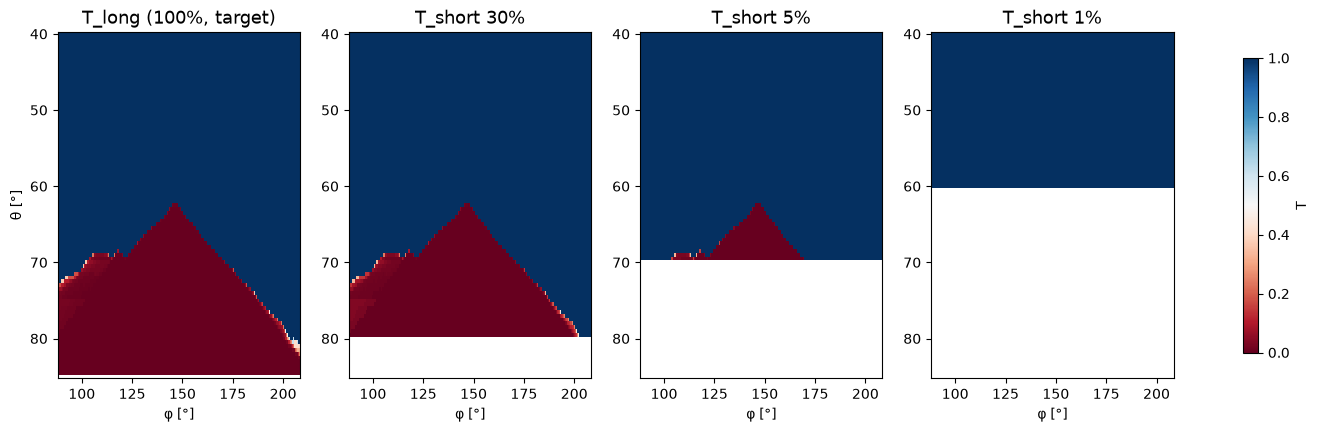

In [6]:
data = np.load(OUT_DIR / "fuego_pairs.npz")
theta_deg_grid, phi_deg_grid = data["theta_deg"], data["phi_deg"]
PHI, THETA = np.meshgrid(phi_deg_grid, theta_deg_grid)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
panels = [
    ("T_long (100%, target)", data["T_long"]),
    ("T_short 30%", data["T_short_f30"][0]),
    ("T_short 5%", data["T_short_f05"][0]),
    ("T_short 1%", data["T_short_f01"][0]),
]
for ax, (title, T) in zip(axes, panels):
    im = ax.pcolormesh(PHI, THETA, T, cmap="RdBu", shading="auto", vmin=0, vmax=1)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("φ [°]")
axes[0].set_ylabel("θ [°]")
fig.colorbar(im, ax=axes, label="T", shrink=0.85)
fig.savefig(OUT_DIR / "preview_fuego_pairs.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Conclusiones — qué sí y qué no demuestra este notebook

**Sí demuestra:**
- El adelgazamiento binomial del pool de muones es indistinguible (KS, y en el
  observable físico `T_mc`) de una corrida CORSIKA real e independiente del mismo
  tamaño — validado contra el sweep real de Fuego (Sección 3).
- Se pueden generar pares (corta, larga exposición) para los 4 volcanes sin asumir
  ningún parámetro de detector (área efectiva, tiempo de exposición real): la
  "exposición corta" se define como fracción de la estadística MC ya simulada.
- A fracciones bajas (1%, 5%) la cola θ>70° — y en Pacaya/Agua incluso más — se
  vuelve enteramente inválida (`NaN`, por debajo de `min_per_bin`), que es
  precisamente el problema que el cWGAN-GP debe resolver.

**NO demuestra (y no se debe afirmar en el paper):**
- Que estos pares por sí solos entrenen ya el modelo — este notebook solo prepara
  los datos; la arquitectura cWGAN-GP, el entrenamiento y la evaluación SSIM/PSNR
  (Sección Methods `sec:methods-cwgan` de `muography_ml.tex`) quedan para el
  siguiente notebook.
- Que la exposición corta corresponda a un número real de días — esa traducción
  requiere fijar área de detector y aceptancia angular, decisión pendiente (ver
  Discussion del Paper 1).

`sim/output/cwgan_pairs/*.npz` (uno por volcán, gitignored) contiene `T_long`,
`n_full`, y `T_short_f{01,05,15,30,50}` (shape `(20, 91, 241)`, 20 realizaciones
independientes cada uno) — listos para el notebook de entrenamiento del cWGAN-GP.